# Analisis Asosiasi Gender pada Jabatan Profesional KBJI 2014 Menggunakan IndoBERT dan w-SEAT

Word-level Sentence Encoder Association Test (w-SEAT) adalah adaptasi logika SC-WEAT pada contextual phrase embedding IndoBERT. Skor utama memakai cosine similarity, association difference, effect size, dan permutation test berbasis WEAT; probabilitas masked token LPBS bukan skor utama.


## Tujuan, data dictionary, dan orientasi

Nama jabatan KBJI kode 21–26 didominasi frasa multi-kata. Kolom utama adalah occupation_code, template_id, lexical_condition, embedding_method, association_score, effect_size, permutation_p, fdr_p, direction, number_of_subtokens, dan alignment_status. Positif berarti relatif lebih dekat ke istilah laki-laki; negatif berarti relatif lebih dekat ke istilah perempuan. Ini asosiasi model intrinsik, bukan fakta sosial.


In [1]:
import itertools, json, math, platform, random, sys, time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, seaborn as sns, torch, transformers
from IPython.display import display
from scipy.stats import kendalltau, kruskal, spearmanr
from statsmodels.stats.multitest import multipletests
from transformers import AutoModel, AutoTokenizer
RANDOM_SEED=42; random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(RANDOM_SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu"); ROOT=Path.cwd(); TABLE_DIR=ROOT/"outputs"/"tables"; TABLE_DIR.mkdir(parents=True,exist_ok=True)
DATA_PATH=ROOT/"data"/"test1_v5_kbji_profesional_clean.csv"; LEXICON_PATH=ROOT/"data"/"test1_v5_gender_lexicon.csv"; MODEL_NAME="indobenchmark/indobert-base-p1"; MAX_LENGTH=512
TIME_START=time.time(); TIME_START_ISO=time.strftime("%Y-%m-%dT%H:%M:%S%z"); assert DATA_PATH.exists() and LEXICON_PATH.exists()
print({"python":sys.version.split()[0],"pytorch":torch.__version__,"transformers":transformers.__version__,"device":str(device),"cuda":torch.cuda.is_available(),"seed":RANDOM_SEED,"model":MODEL_NAME})


C:\Users\Wiraditya\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.14.0', 'pytorch': '2.12.1+cpu', 'transformers': '4.57.6', 'device': 'cpu', 'cuda': False, 'seed': 42, 'model': 'indobenchmark/indobert-base-p1'}


## Membaca CSV final

CSV test1_v5 dibaca tanpa ekstraksi atau pembersihan ulang. Kode dibaca sebagai string dan analisis memakai include_analysis.


In [2]:
df=pd.read_csv(DATA_PATH,dtype={"occupation_code":str,"major_group_code":str,"submajor_group_code":str,"group_code":str,"subgroup_code":str,"source_page_printed":str}); gender_lexicon=pd.read_csv(LEXICON_PATH); df_analysis=df[df["include_analysis"]].copy(); df_analysis["occupation_text"]=df_analysis["occupation_name"].str.lower(); allowed_groups={"21","22","23","24","25","26"}
display(df.head()); display(df.sample(min(5,len(df)),random_state=RANDOM_SEED)); df.info(); display(df.isna().sum().rename("missing").to_frame()); display(df_analysis.groupby(["submajor_group_code","submajor_group_name"]).size().rename("occupation_count").reset_index())
assert len(df_analysis)==415 and set(df_analysis["submajor_group_code"])==allowed_groups


,occupation_code,occupation_name,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,subgroup_code,subgroup_name,...,is_valid_code,is_duplicate_code,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_name,name_nonempty,include_analysis
0,2111.01,Ahli Fisika (Umum),2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,...,True,False,False,False,True,True,False,False,True,True
1,2111.02,Ahli Fisika Nuklir,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,...,True,False,False,False,True,True,False,False,True,True
2,2111.03,Ahli Fisika Mekanika,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,...,True,False,False,False,True,True,False,False,True,True
3,2111.04,Ahli Fisika Panas,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,...,True,False,False,False,True,True,False,False,True,True
4,2111.05,Ahli Fisika Sinar,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,...,True,False,False,False,True,True,False,False,True,True


,occupation_code,occupation_name,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,subgroup_code,subgroup_name,...,is_valid_code,is_duplicate_code,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_name,name_nonempty,include_analysis
362,2521.02,Analis Database,2,Profesional,25,Profesional teknologi informasi dan komunikasi,252,Profesional Database dan Jaringan,2521,Pengelola dan Perancang Database,...,True,False,False,False,True,True,False,False,True,True
73,2142.04,Ahli Teknik Konstruksi Landasan Pesawat Udara.,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,214,Ahli Teknik (Selain Ahli Teknologi Elektro),2142,Ahli Teknik Sipil,...,True,False,False,False,True,True,False,False,True,True
375,2611.02,Jaksa,2,Profesional,26,"Profesional hukum, sosial dan budaya",261,Profesional Hukum,2611,Pengacara,...,True,False,False,False,True,True,False,False,True,True
155,2166.06,Ilustrator,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,216,"Arsitek, Perencana, Surveyor dan Desainer",2166,Perancang Grafis dan Multimedia,...,True,False,False,False,True,True,False,False,True,True
104,2146.99,"Ahli Teknik Pertambangan, Metalurgi dan YBDI L...",2,Profesional,21,Ahli ilmu pengetahuan dan teknik,214,Ahli Teknik (Selain Ahli Teknologi Elektro),2146,"Ahli Teknik Pertambangan, Metalurgi dan YBDI",...,True,False,True,False,True,True,False,False,True,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   occupation_code            501 non-null    object
 1   occupation_name            501 non-null    object
 2   major_group_code           501 non-null    object
 3   major_group_name           501 non-null    object
 4   submajor_group_code        501 non-null    object
 5   submajor_group_name        501 non-null    object
 6   group_code                 501 non-null    object
 7   group_name                 501 non-null    object
 8   subgroup_code              501 non-null    object
 9   subgroup_name              501 non-null    object
 10  source_document            501 non-null    object
 11  source_page_pdf            501 non-null    int64 
 12  source_page_printed        501 non-null    object
 13  preprocessing_version      501 non-null    object
 14  token_coun

,missing
occupation_code,0
occupation_name,0
major_group_code,0
major_group_name,0
submajor_group_code,0
submajor_group_name,0
group_code,0
group_name,0
subgroup_code,0
subgroup_name,0


,submajor_group_code,submajor_group_name,occupation_count
0,21,Ahli ilmu pengetahuan dan teknik,138
1,22,Profesional kesehatan,74
2,23,Profesional pendidikan,42
3,24,Profesional bisnis dan administrasi,29
4,25,Profesional teknologi informasi dan komunikasi,26
5,26,"Profesional hukum, sosial dan budaya",106


## Memuat IndoBERT sebagai contextual encoder

AutoModel dipakai untuk hidden state, bukan probabilitas masked token. Model eval dan inference mode digunakan. Revision, tokenizer, vocabulary, layer, parameter, dan device dicatat.


In [3]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME); model=AutoModel.from_pretrained(MODEL_NAME,output_hidden_states=True).to(device); model.eval(); MODEL_REVISION=getattr(model.config,"_commit_hash",None) or getattr(model,"_commit_hash",None) or tokenizer.init_kwargs.get("_commit_hash","unknown")
model_audit=pd.DataFrame([{"model_name":MODEL_NAME,"model_revision":MODEL_REVISION,"tokenizer":tokenizer.__class__.__name__,"vocabulary_size":len(tokenizer),"hidden_size":model.config.hidden_size,"num_hidden_layers":model.config.num_hidden_layers,"parameter_count":sum(p.numel() for p in model.parameters()),"device":str(device),"source":"Hugging Face Hub"}]); display(model_audit)


,model_name,model_revision,tokenizer,vocabulary_size,hidden_size,num_hidden_layers,parameter_count,device,source
0,indobenchmark/indobert-base-p1,c2cd0b51ddce6580eb35263b39b0a1e5fb0a39e2,BertTokenizerFast,30521,768,12,124441344,cpu,Hugging Face Hub


## Template semantically bleached dan katalog

Empat template ditetapkan sebelum melihat hasil dan menempatkan term sebagai frasa nominal. manually_reviewed=False berarti belum ada validator manusia.


In [4]:
template_catalog=pd.DataFrame([
{"template_id":"T1","template_text":"Ini adalah {term}.","template_type":"semantically bleached","grammatical_role":"komplemen nominal","source_or_rationale":"Kopula sederhana; konteks minimal.","manually_reviewed":False,"review_notes":"Tinjauan linguistik manusia diperlukan."},
{"template_id":"T2","template_text":"Istilah tersebut adalah {term}.","template_type":"semantically bleached","grammatical_role":"komplemen nominal","source_or_rationale":"Pengantar istilah netral.","manually_reviewed":False,"review_notes":"Tinjauan linguistik manusia diperlukan."},
{"template_id":"T3","template_text":"{term} tersebut ada di sini.","template_type":"semantically bleached","grammatical_role":"subjek nominal","source_or_rationale":"Term sebagai subjek dengan predikat keberadaan.","manually_reviewed":False,"review_notes":"Tinjauan linguistik manusia diperlukan."},
{"template_id":"T4","template_text":"Contoh yang dimaksud adalah {term}.","template_type":"semantically bleached","grammatical_role":"komplemen nominal","source_or_rationale":"Konteks rujukan netral.","manually_reviewed":False,"review_notes":"Tinjauan linguistik manusia diperlukan."}]); display(template_catalog)


,template_id,template_text,template_type,grammatical_role,source_or_rationale,manually_reviewed,review_notes
0,T1,Ini adalah {term}.,semantically bleached,komplemen nominal,Kopula sederhana; konteks minimal.,False,Tinjauan linguistik manusia diperlukan.
1,T2,Istilah tersebut adalah {term}.,semantically bleached,komplemen nominal,Pengantar istilah netral.,False,Tinjauan linguistik manusia diperlukan.
2,T3,{term} tersebut ada di sini.,semantically bleached,subjek nominal,Term sebagai subjek dengan predikat keberadaan.,False,Tinjauan linguistik manusia diperlukan.
3,T4,Contoh yang dimaksud adalah {term}.,semantically bleached,komplemen nominal,Konteks rujukan netral.,False,Tinjauan linguistik manusia diperlukan.


## Alignment subtoken dan contextual phrase embedding

Offset mapping menemukan subtoken yang overlap dengan rentang karakter term. Mean pooling hanya pada span term lalu L2 normalization. Last layer adalah kondisi utama; mean empat layer terakhir adalah sensitivitas.


In [5]:
def embed_target_batch(terms,template_text,method,batch_size=32):
    vectors=[]; audits=[]
    for start in range(0,len(terms),batch_size):
        bt=list(terms[start:start+batch_size]); texts=[]; spans=[]
        for term in bt:
            text=template_text.format(term=term); left=text.index(term); texts.append(text); spans.append((left,left+len(term)))
        enc=tokenizer(texts,return_offsets_mapping=True,padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors="pt"); offsets=enc.pop("offset_mapping").tolist(); enc={k:v.to(device) for k,v in enc.items()}
        with torch.inference_mode(): out=model(**enc,output_hidden_states=True)
        hidden=out.hidden_states[-1] if method=="last_layer_target_mean" else torch.stack(out.hidden_states[-4:]).mean(dim=0)
        for i,(term,span) in enumerate(zip(bt,spans)):
            matched=[j for j,(a,b) in enumerate(offsets[i]) if b>span[0] and a<span[1]]
            if not matched:
                vectors.append(np.full(model.config.hidden_size,np.nan)); audits.append({"term":term,"tokens":"","token_ids":"","number_of_subtokens":0,"matched_character_span":str(span),"alignment_status":"failed","embedding_norm":np.nan,"embedding_method":method}); continue
            pooled=hidden[i,matched,:].mean(dim=0); norm=torch.linalg.vector_norm(pooled).item(); vectors.append((pooled/max(norm,torch.finfo(pooled.dtype).eps)).detach().cpu().numpy()); ids=[enc["input_ids"][i,j].item() for j in matched]
            audits.append({"term":term,"tokens":" | ".join(tokenizer.convert_ids_to_tokens(ids)),"token_ids":" | ".join(map(str,ids)),"number_of_subtokens":len(matched),"matched_character_span":str(span),"alignment_status":"matched","embedding_norm":norm,"embedding_method":method})
    return np.asarray(vectors),audits
embedding_methods=["last_layer_target_mean","mean_four_last_layers_target"]; occupation_embeddings={}; gender_embeddings={}; audit_rows=[]; all_gender_terms=pd.unique(pd.concat([gender_lexicon["male_term"],gender_lexicon["female_term"]],ignore_index=True)).tolist()
for t in template_catalog.itertuples(index=False):
    for method in embedding_methods:
        occ,oa=embed_target_batch(df_analysis["occupation_name"].tolist(),t.template_text,method); gen,ga=embed_target_batch(all_gender_terms,t.template_text,method); occupation_embeddings[(t.template_id,method)]=occ; gender_embeddings[(t.template_id,method)]={term:vec for term,vec in zip(all_gender_terms,gen)}
        audit_rows += [{**x,"template_id":t.template_id,"target_type":"occupation"} for x in oa] + [{**x,"template_id":t.template_id,"target_type":"gender"} for x in ga]
contextual_embedding_audit=pd.DataFrame(audit_rows); display(contextual_embedding_audit.head(20)); display(contextual_embedding_audit.groupby(["target_type","embedding_method","alignment_status"]).size().rename("count").reset_index())


,term,tokens,token_ids,number_of_subtokens,matched_character_span,alignment_status,embedding_norm,embedding_method,template_id,target_type
0,Ahli Fisika (Umum),ahli | fisika | ( | umum | ),2426 | 5940 | 30464 | 752 | 30465,5,"(11, 29)",matched,20.860212,last_layer_target_mean,T1,occupation
1,Ahli Fisika Nuklir,ahli | fisika | nuklir,2426 | 5940 | 10061,3,"(11, 29)",matched,23.133827,last_layer_target_mean,T1,occupation
2,Ahli Fisika Mekanika,ahli | fisika | mekanika,2426 | 5940 | 29524,3,"(11, 31)",matched,23.046476,last_layer_target_mean,T1,occupation
3,Ahli Fisika Panas,ahli | fisika | panas,2426 | 5940 | 1990,3,"(11, 28)",matched,22.940180,last_layer_target_mean,T1,occupation
4,Ahli Fisika Sinar,ahli | fisika | sinar,2426 | 5940 | 4436,3,"(11, 28)",matched,22.658947,last_layer_target_mean,T1,occupation
5,Ahli Fisika Suara,ahli | fisika | suara,2426 | 5940 | 1699,3,"(11, 28)",matched,22.628084,last_layer_target_mean,T1,occupation
6,Ahli Fisika Listrik Dan Magnit,ahli | fisika | listrik | dan | magn | ##it,2426 | 5940 | 2235 | 41 | 11636 | 47,6,"(11, 41)",matched,20.045311,last_layer_target_mean,T1,occupation
7,Ahli Fisika Elektronika,ahli | fisika | elektronika,2426 | 5940 | 17206,3,"(11, 34)",matched,22.782064,last_layer_target_mean,T1,occupation
8,Ahli Fisika Medis,ahli | fisika | medis,2426 | 5940 | 5049,3,"(11, 28)",matched,22.768446,last_layer_target_mean,T1,occupation
9,Ahli Astronomi,ahli | astronomi,2426 | 18373,2,"(11, 25)",matched,24.201742,last_layer_target_mean,T1,occupation


,target_type,embedding_method,alignment_status,count
0,gender,last_layer_target_mean,matched,64
1,gender,mean_four_last_layers_target,matched,64
2,occupation,last_layer_target_mean,matched,1660
3,occupation,mean_four_last_layers_target,matched,1660


## Quality control alignment

Seluruh jabatan dan istilah gender harus matched. Norm embedding sebelum normalisasi harus finite dan positif; kegagalan tidak dihapus.


In [6]:
alignment_qc=pd.DataFrame([{"check":"alignment matched","status":contextual_embedding_audit["alignment_status"].eq("matched").all(),"observed":contextual_embedding_audit["alignment_status"].value_counts().to_dict()},{"check":"norm finite positif","status":bool(np.isfinite(contextual_embedding_audit["embedding_norm"]).all() and (contextual_embedding_audit["embedding_norm"]>0).all()),"observed":contextual_embedding_audit["embedding_norm"].describe().to_dict()},{"check":"occupation audit lengkap","status":len(contextual_embedding_audit[contextual_embedding_audit["target_type"].eq("occupation")])==len(df_analysis)*len(template_catalog)*len(embedding_methods),"observed":len(contextual_embedding_audit)}]); display(alignment_qc); assert alignment_qc["status"].all()


,check,status,observed
0,alignment matched,True,{'matched': 3448}
1,norm finite positif,True,"{'count': 3448.0, 'mean': 22.11925483220138, '..."
2,occupation audit lengkap,True,3448


## Perhitungan w-SEAT dan exact permutation

Association score adalah mean cosine target ke istilah laki-laki dikurangi mean cosine ke istilah perempuan. Effect size membagi difference dengan simpangan baku sampel seluruh similarity. Exact permutation mengacak label dengan jumlah kelas tetap; FDR diterapkan per kondisi, template, dan pooling.


In [7]:
condition_pairs={"core_identity":gender_lexicon.loc[gender_lexicon["include_core"],"pair_id"].tolist(),"kinship":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("kinship"),"pair_id"].tolist(),"age_status":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("age_status"),"pair_id"].tolist(),"informal":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("informal"),"pair_id"].tolist(),"existing_full":gender_lexicon["pair_id"].tolist()}
pair_lookup=gender_lexicon.set_index("pair_id").to_dict("index"); permutation_masks={n:np.asarray([[int(i in s) for i in range(2*n)] for s in itertools.combinations(range(2*n),n)],dtype=float) for n in sorted({len(x) for x in condition_pairs.values()})}; score_rows=[]
for t in template_catalog.itertuples(index=False):
    for method in embedding_methods:
        om=occupation_embeddings[(t.template_id,method)]; gm=gender_embeddings[(t.template_id,method)]
        for condition,pids in condition_pairs.items():
            mt=[pair_lookup[p]["male_term"] for p in pids]; ft=[pair_lookup[p]["female_term"] for p in pids]; masks=permutation_masks[len(pids)]
            for i,row in enumerate(df_analysis.itertuples(index=False)):
                ms=om[i]@np.asarray([gm[x] for x in mt]).T; fs=om[i]@np.asarray([gm[x] for x in ft]).T; sims=np.concatenate([ms,fs]); assoc=float(ms.mean()-fs.mean()); sd=float(sims.std(ddof=1)); eff=assoc/sd if sd>0 else np.nan; perm=(masks@sims)/len(pids)-((1-masks)@sims)/len(pids); p=float(np.mean(np.abs(perm)>=abs(assoc)))
                score_rows.append({"occupation_code":row.occupation_code,"occupation_name":row.occupation_name,"major_group_code":row.major_group_code,"major_group_name":row.major_group_name,"kbji_group_code":row.submajor_group_code,"kbji_group_name":row.submajor_group_name,"kbji_detail_code":row.group_code,"kbji_detail_name":row.group_name,"template_id":t.template_id,"lexical_condition":condition,"embedding_method":method,"association_score":assoc,"similarity_standard_deviation":sd,"effect_size":eff,"permutation_p":p,"exact_partition_count":len(masks),"direction":"positif" if assoc>0 else "negatif" if assoc<0 else "nol","number_of_subtokens":int(contextual_embedding_audit[(contextual_embedding_audit["target_type"].eq("occupation"))&contextual_embedding_audit["template_id"].eq(t.template_id)&contextual_embedding_audit["embedding_method"].eq(method)&contextual_embedding_audit["term"].eq(row.occupation_name)]["number_of_subtokens"].iloc[0]),"alignment_status":"matched"})
wseat_scores_long=pd.DataFrame(score_rows); wseat_scores_long["fdr_p"]=np.nan
for _,idx in wseat_scores_long.groupby(["lexical_condition","template_id","embedding_method"]).groups.items(): wseat_scores_long.loc[idx,"fdr_p"]=multipletests(wseat_scores_long.loc[idx,"permutation_p"],method="fdr_bh")[1]
display(wseat_scores_long.head()); display(wseat_scores_long.groupby(["lexical_condition","embedding_method"]).size().rename("rows").reset_index())


,occupation_code,occupation_name,major_group_code,major_group_name,kbji_group_code,kbji_group_name,kbji_detail_code,kbji_detail_name,template_id,lexical_condition,embedding_method,association_score,similarity_standard_deviation,effect_size,permutation_p,exact_partition_count,direction,number_of_subtokens,alignment_status,fdr_p
0,2111.01,Ahli Fisika (Umum),2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,core_identity,last_layer_target_mean,-0.022858,0.019347,-1.181521,0.666667,6,negatif,5,matched,0.75592
1,2111.02,Ahli Fisika Nuklir,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,core_identity,last_layer_target_mean,-0.037294,0.041439,-0.899991,0.666667,6,negatif,3,matched,0.75592
2,2111.03,Ahli Fisika Mekanika,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,core_identity,last_layer_target_mean,-0.018955,0.024340,-0.778778,0.666667,6,negatif,3,matched,0.75592
3,2111.04,Ahli Fisika Panas,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,core_identity,last_layer_target_mean,-0.022055,0.019981,-1.103798,0.666667,6,negatif,3,matched,0.75592
4,2111.05,Ahli Fisika Sinar,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,core_identity,last_layer_target_mean,-0.013741,0.013497,-1.018027,0.666667,6,negatif,3,matched,0.75592


,lexical_condition,embedding_method,rows
0,age_status,last_layer_target_mean,1660
1,age_status,mean_four_last_layers_target,1660
2,core_identity,last_layer_target_mean,1660
3,core_identity,mean_four_last_layers_target,1660
4,existing_full,last_layer_target_mean,1660
5,existing_full,mean_four_last_layers_target,1660
6,informal,last_layer_target_mean,1660
7,informal,mean_four_last_layers_target,1660
8,kinship,last_layer_target_mean,1660
9,kinship,mean_four_last_layers_target,1660


Core identity adalah kondisi utama yang ditetapkan sebelum eksekusi. Kategori lain dibaca sebagai sensitivitas semantik; core hanya enam pembagian exact.


## Agregasi jabatan dan kelompok

Median lintas template pada core/last layer adalah skor utama. Statistik tambahan mencakup mean, median, standar deviasi, IQR, MAD, min, max, proporsi tanda, agreement, dan sign flip.


In [8]:
main_scores=wseat_scores_long[(wseat_scores_long["lexical_condition"]=="core_identity")&(wseat_scores_long["embedding_method"]=="last_layer_target_mean")].copy()
occupation_summary=main_scores.groupby(["occupation_code","occupation_name","kbji_group_code","kbji_group_name"],as_index=False).agg(mean_effect_size=("effect_size","mean"),median_effect_size=("effect_size","median"),std_effect_size=("effect_size","std"),minimum_effect_size=("effect_size","min"),maximum_effect_size=("effect_size","max"),positive_template_proportion=("effect_size",lambda x:float((x>0).mean())),negative_template_proportion=("effect_size",lambda x:float((x<0).mean())))
q=main_scores.groupby("occupation_code")["effect_size"].quantile([.25,.75]).unstack(); occupation_summary["iqr_effect_size"]=occupation_summary["occupation_code"].map(q[.75]-q[.25]); occupation_summary["mad_effect_size"]=occupation_summary["occupation_code"].map(main_scores.groupby("occupation_code")["effect_size"].apply(lambda x:float((x-x.median()).abs().mean()))); occupation_summary["score_range"]=occupation_summary["maximum_effect_size"]-occupation_summary["minimum_effect_size"]
pm=main_scores.pivot(index="occupation_code",columns="template_id",values="effect_size"); occupation_summary["median_sign_agreement"]=occupation_summary["occupation_code"].map(pm.apply(lambda x:max((x>0).sum(),(x<0).sum(),(x==0).sum())/len(x),axis=1)); occupation_summary["sign_flip_count"]=occupation_summary["occupation_code"].map(pm.apply(lambda x:int((np.sign(x)!=np.sign(x.median())).sum()),axis=1)); occupation_summary["direction"]=np.select([occupation_summary["median_effect_size"]>0,occupation_summary["median_effect_size"]<0],["positif","negatif"],default="nol"); occupation_summary["valid_template_count"]=occupation_summary["occupation_code"].map(main_scores.groupby("occupation_code").size())
display(occupation_summary.head()); display(occupation_summary["direction"].value_counts().rename("occupation_count").to_frame()); display(occupation_summary.nlargest(15,"median_effect_size")[["occupation_code","occupation_name","median_effect_size","median_sign_agreement"]]); display(occupation_summary.nsmallest(15,"median_effect_size")[["occupation_code","occupation_name","median_effect_size","median_sign_agreement"]])


,occupation_code,occupation_name,kbji_group_code,kbji_group_name,mean_effect_size,median_effect_size,std_effect_size,minimum_effect_size,maximum_effect_size,positive_template_proportion,negative_template_proportion,iqr_effect_size,mad_effect_size,score_range,median_sign_agreement,sign_flip_count,direction,valid_template_count
0,2111.01,Ahli Fisika (Umum),21,Ahli ilmu pengetahuan dan teknik,-0.692886,-0.555535,0.332340,-1.181521,-0.478954,0.0,1.0,0.276753,0.209345,0.702567,1.0,0,negatif,4
1,2111.02,Ahli Fisika Nuklir,21,Ahli ilmu pengetahuan dan teknik,-0.781790,-0.776660,0.093167,-0.899991,-0.673850,0.0,1.0,0.076795,0.063289,0.226141,1.0,0,negatif,4
2,2111.03,Ahli Fisika Mekanika,21,Ahli ilmu pengetahuan dan teknik,-0.647134,-0.667004,0.260172,-0.924334,-0.330192,0.0,1.0,0.316196,0.204422,0.594143,1.0,0,negatif,4
3,2111.04,Ahli Fisika Panas,21,Ahli ilmu pengetahuan dan teknik,-0.788492,-0.715755,0.225712,-1.103798,-0.618662,0.0,1.0,0.246766,0.163112,0.485136,1.0,0,negatif,4
4,2111.05,Ahli Fisika Sinar,21,Ahli ilmu pengetahuan dan teknik,-0.767789,-0.768890,0.276412,-1.018027,-0.515348,0.0,1.0,0.465846,0.239062,0.502679,1.0,0,negatif,4


,occupation_count
direction,
negatif,396
positif,19


,occupation_code,occupation_name,median_effect_size,median_sign_agreement
222,2310.11,"Dosen Ilmu Bahasa, Sastra, Budaya dan Sejarah",1.627117,1.00
6,2111.07,Ahli Fisika Listrik Dan Magnit,1.214129,1.00
374,2643.03,Ahli Filologi (Manuskrip),1.072403,1.00
81,2144.09,Ahli Teknik Mesin Tenaga Atom,1.038959,0.75
95,2149.05,Ahli Teknik Perencanaan Sistem Lalu-Lintas,1.010178,1.00
354,2636.06,Pendeta Kong Hu Cu,0.983489,1.00
143,2212.04,"Dokter Spesialis Telinga, Hidung dan Tenggorokan",0.863338,1.00
107,2152.03,Ahli Teknik Instrumentasi (Alat Ukur),0.822063,0.75
335,2633.04,Ahli Genealogi (Ahli Silsilah),0.645439,1.00
80,2144.08,"Ahli Teknik Pemanasan, Ventilasi dan Pendinginan",0.506454,1.00


,occupation_code,occupation_name,median_effect_size,median_sign_agreement
144,2212.05,Dokter Spesialis Kandungan,-1.724269,1.00
155,2212.16,Dokter Spesialis Bedah Syaraf,-1.687968,1.00
141,2212.02,Dokter Spesialis Jantung,-1.678918,1.00
329,2632.03,Ahi Etnologi,-1.675846,1.00
41,2131.11,Ahli Patologis Medis,-1.644577,1.00
140,2212.01,Dokter Spesialis Anestesi,-1.639773,1.00
153,2212.14,Dokter Spesialis Bedah Umum,-1.633666,1.00
145,2212.06,Dokter Spesialis Mata,-1.624054,1.00
152,2212.13,Dokter Spesialis Radiologi,-1.599729,1.00
213,2310.02,Dosen Ilmu Teknik dan Arsitektur,-1.592661,1.00


Arah positif/negatif adalah arah relatif model. Skor ekstrem ditampilkan deskriptif dan harus dibaca bersama stabilitas template.


## Bootstrap kelompok dan uji perbandingan

Bootstrap memakai kbji_detail_code sebagai cluster dengan 5.000 repetisi dan seed 42. Kruskal–Wallis dan Dunn bersifat eksploratif karena struktur hierarkis KBJI.


In [9]:
BOOTSTRAP_REPETITIONS=5000; rng=np.random.default_rng(RANDOM_SEED); group_rows=[]
for gc,g in occupation_summary.groupby("kbji_group_code"):
    vals=g["median_effect_size"].to_numpy(); detail=main_scores.drop_duplicates("occupation_code").set_index("occupation_code")["kbji_detail_code"].reindex(g["occupation_code"]).astype(str).to_numpy(); clusters=np.unique(detail); boots=[]
    for _ in range(BOOTSTRAP_REPETITIONS):
        sampled=rng.choice(clusters,size=len(clusters),replace=True); boots.append(np.median(np.concatenate([vals[detail==c] for c in sampled])))
    group_rows.append({"kbji_group_code":gc,"kbji_group_name":g["kbji_group_name"].iloc[0],"occupation_count":len(g),"mean_effect_size":vals.mean(),"median_effect_size":np.median(vals),"std_effect_size":vals.std(ddof=1),"iqr_effect_size":np.quantile(vals,.75)-np.quantile(vals,.25),"minimum_effect_size":vals.min(),"maximum_effect_size":vals.max(),"positive_proportion":(vals>0).mean(),"negative_proportion":(vals<0).mean(),"median_sign_agreement":g["median_sign_agreement"].median(),"bootstrap_ci_lower":np.percentile(boots,2.5),"bootstrap_ci_upper":np.percentile(boots,97.5),"bootstrap_repetitions":BOOTSTRAP_REPETITIONS,"bootstrap_unit":"kbji_detail_code"})
group_summary=pd.DataFrame(group_rows); arrays=[g["median_effect_size"].to_numpy() for _,g in occupation_summary.groupby("kbji_group_code")]; kw_stat,kw_p=kruskal(*arrays); epsilon_squared=max(0,(kw_stat-len(arrays)+1)/(len(occupation_summary)-len(arrays)))
statistical_tests=pd.DataFrame([{"test":"Kruskal-Wallis","statistic":kw_stat,"p_value":kw_p,"effect_size":epsilon_squared,"interpretation":"eksploratif; struktur KBJI dapat membuat skor tidak independen"},{"test":"epsilon-squared","statistic":epsilon_squared,"p_value":np.nan,"effect_size":epsilon_squared,"interpretation":"ukuran efek omnibus"}]); posthoc=[] 
if kw_p<.05:
    ranked=occupation_summary[["kbji_group_code","median_effect_size"]].copy(); ranked["rank"]=ranked["median_effect_size"].rank(); from scipy.stats import norm
    for a,b in itertools.combinations(sorted(allowed_groups),2):
        left=ranked[ranked["kbji_group_code"].eq(a)]; right=ranked[ranked["kbji_group_code"].eq(b)]; se=math.sqrt((len(ranked)*(len(ranked)+1)/12)*(1/len(left)+1/len(right))); z=(left["rank"].mean()-right["rank"].mean())/se; posthoc.append({"group_a":a,"group_b":b,"z":z,"p_value":2*norm.sf(abs(z))})
posthoc_dunn=pd.DataFrame(posthoc,columns=["group_a","group_b","z","p_value"])
if len(posthoc_dunn): posthoc_dunn["p_value_bh"]=multipletests(posthoc_dunn["p_value"],method="fdr_bh")[1]; posthoc_dunn["significant_bh_0_05"]=posthoc_dunn["p_value_bh"]<.05
else: posthoc_dunn=pd.DataFrame([{"group_a":"not_run","group_b":"not_run","z":np.nan,"p_value":np.nan,"p_value_bh":np.nan,"significant_bh_0_05":False}])
display(group_summary); display(statistical_tests); display(posthoc_dunn)


,kbji_group_code,kbji_group_name,occupation_count,mean_effect_size,median_effect_size,std_effect_size,iqr_effect_size,minimum_effect_size,maximum_effect_size,positive_proportion,negative_proportion,median_sign_agreement,bootstrap_ci_lower,bootstrap_ci_upper,bootstrap_repetitions,bootstrap_unit
0,21,Ahli ilmu pengetahuan dan teknik,138,-0.863934,-0.978748,0.525858,0.494278,-1.644577,1.214129,0.079710,0.920290,1.0,-1.096919,-0.780930,5000,kbji_detail_code
1,22,Profesional kesehatan,74,-1.230623,-1.293333,0.365213,0.348067,-1.724269,0.863338,0.013514,0.986486,1.0,-1.405414,-1.197248,5000,kbji_detail_code
2,23,Profesional pendidikan,42,-0.870997,-0.955954,0.558889,0.408455,-1.592661,1.627117,0.071429,0.928571,1.0,-1.141008,-0.825430,5000,kbji_detail_code
3,24,Profesional bisnis dan administrasi,29,-0.883306,-0.929754,0.311622,0.244165,-1.213405,0.430204,0.034483,0.965517,1.0,-1.084393,-0.822230,5000,kbji_detail_code
4,25,Profesional teknologi informasi dan komunikasi,26,-1.026453,-1.039767,0.187441,0.288033,-1.345303,-0.690774,0.000000,1.000000,1.0,-1.048948,-1.030585,5000,kbji_detail_code
5,26,"Profesional hukum, sosial dan budaya",106,-0.945829,-0.985335,0.403381,0.267288,-1.675846,1.072403,0.028302,0.971698,1.0,-1.027170,-0.950233,5000,kbji_detail_code


,test,statistic,p_value,effect_size,interpretation
0,Kruskal-Wallis,58.581764,2.385827e-11,0.131007,eksploratif; struktur KBJI dapat membuat skor ...
1,epsilon-squared,0.131007,NaN,0.131007,ukuran efek omnibus


,group_a,group_b,z,p_value,p_value_bh,significant_bh_0_05
0,21,22,6.789529,1.125000e-11,1.687500e-10,True
1,21,23,-0.020471,9.836673e-01,9.836673e-01,False
2,21,24,-1.018320,3.085259e-01,5.651988e-01,False
3,21,25,0.935609,3.494747e-01,5.651988e-01,False
4,21,26,0.565718,5.715853e-01,6.595215e-01,False
5,22,23,-5.082324,3.728448e-07,1.398168e-06,True
6,22,24,-5.414789,6.136111e-08,3.068055e-07,True
7,22,25,-3.413573,6.411697e-04,1.923509e-03,True
8,22,26,-5.975482,2.294106e-09,1.720580e-08,True
9,23,24,-0.846643,3.971939e-01,5.651988e-01,False


Bootstrap CI yang melintasi nol menunjukkan arah kelompok belum pasti. Uji inferensial hanya eksploratif dan tidak menjadi klaim sosial.


## Sensitivitas template dan leave-one-template-out

Korelasi Spearman/Kendall, agreement tanda, sign flip, dan mean absolute difference dihitung pada skor jabatan. Leave-one-template-out mengagregasikan ulang template yang tersisa.


In [10]:
template_stability_rows=[]
for a,b in itertools.combinations(pm.columns,2):
    x=pm[[a,b]].dropna(); template_stability_rows.append({"template_a":a,"template_b":b,"spearman":spearmanr(x[a],x[b]).statistic,"kendall":kendalltau(x[a],x[b]).statistic,"sign_agreement":float((np.sign(x[a])==np.sign(x[b])).mean()),"sign_flip_count":int((np.sign(x[a])!=np.sign(x[b])).sum()),"mean_absolute_difference":float((x[a]-x[b]).abs().mean())})
template_stability=pd.DataFrame(template_stability_rows); full_scores=pm.median(axis=1); loo_rows=[]
for omitted in pm.columns:
    loo=pm.drop(columns=omitted).median(axis=1); x=pd.DataFrame({"full":full_scores,"loo":loo}).dropna(); loo_rows.append({"omitted_template":omitted,"spearman":spearmanr(x["full"],x["loo"]).statistic,"kendall":kendalltau(x["full"],x["loo"]).statistic,"sign_agreement":float((np.sign(x["full"])==np.sign(x["loo"])).mean()),"sign_flip_count":int((np.sign(x["full"])!=np.sign(x["loo"])).sum()),"mean_absolute_difference":float((x["full"]-x["loo"]).abs().mean()),"mean_absolute_rank_change":float((x["full"].rank()-x["loo"].rank()).abs().mean())})
leave_one_template_out=pd.DataFrame(loo_rows); display(template_stability); display(leave_one_template_out)


,template_a,template_b,spearman,kendall,sign_agreement,sign_flip_count,mean_absolute_difference
0,T1,T2,0.789376,0.631384,0.975904,10,0.281166
1,T1,T3,0.271211,0.187894,0.949398,21,0.420317
2,T1,T4,0.710214,0.544474,0.963855,15,0.273481
3,T2,T3,0.351455,0.246400,0.944578,23,0.488695
4,T2,T4,0.831856,0.694151,0.963855,15,0.185486
5,T3,T4,0.203296,0.144078,0.951807,20,0.468938


,omitted_template,spearman,kendall,sign_agreement,sign_flip_count,mean_absolute_difference,mean_absolute_rank_change
0,T1,0.949254,0.825109,0.985542,6,0.092172,24.954217
1,T2,0.957327,0.848367,0.992771,3,0.092172,21.595181
2,T3,0.952248,0.834259,0.990361,4,0.092172,23.706024
3,T4,0.956611,0.838682,0.992771,3,0.092172,23.320482


Agreement antartemplate yang rendah adalah bukti sensitivitas formulasi kalimat dan dilaporkan, bukan alasan membuang template.


## Sensitivitas lexical condition dan leave-one-pair-out

Kategori lexical dipisahkan. Leave-one-pair-out mengeluarkan satu pasangan dari existing full dan menghitung ulang association/effect size dari embedding yang sama.


In [11]:
condition_rows=[]
for condition,frame in wseat_scores_long[wseat_scores_long["embedding_method"].eq("last_layer_target_mean")].groupby("lexical_condition"):
    agg=frame.groupby("occupation_code")["effect_size"].median()
    for oc,val in agg.items():
        r=df_analysis.set_index("occupation_code").loc[oc]; condition_rows.append({"occupation_code":oc,"occupation_name":r["occupation_name"],"kbji_group_code":r["submajor_group_code"],"lexical_condition":condition,"median_effect_size":val,"direction":"positif" if val>0 else "negatif" if val<0 else "nol"})
lexical_condition_comparison=pd.DataFrame(condition_rows); existing=lexical_condition_comparison[lexical_condition_comparison["lexical_condition"].eq("existing_full")].set_index("occupation_code")["median_effect_size"]; loo_pair_rows=[]; existing_pair_ids=condition_pairs["existing_full"]
for omitted in existing_pair_ids:
    kept=[p for p in existing_pair_ids if p!=omitted]
    for t in template_catalog.itertuples(index=False):
        occ=occupation_embeddings[(t.template_id,"last_layer_target_mean")]; gen=gender_embeddings[(t.template_id,"last_layer_target_mean")]; mt=[pair_lookup[p]["male_term"] for p in kept]; ft=[pair_lookup[p]["female_term"] for p in kept]
        for i,r in enumerate(df_analysis.itertuples(index=False)):
            ms=occ[i]@np.asarray([gen[x] for x in mt]).T; fs=occ[i]@np.asarray([gen[x] for x in ft]).T; sims=np.concatenate([ms,fs]); assoc=ms.mean()-fs.mean(); sd=sims.std(ddof=1); eff=assoc/sd if sd>0 else np.nan; loo_pair_rows.append({"occupation_code":r.occupation_code,"occupation_name":r.occupation_name,"template_id":t.template_id,"omitted_pair_id":omitted,"association_score_loo":assoc,"effect_size_loo":eff,"direction":"positif" if eff>0 else "negatif" if eff<0 else "nol"})
leave_one_pair_out=pd.DataFrame(loo_pair_rows); loo_pair_summary=leave_one_pair_out.groupby(["occupation_code","omitted_pair_id"],as_index=False)["effect_size_loo"].median().rename(columns={"effect_size_loo":"median_effect_size_loo"}); loo_pair_summary["full_median_effect_size"]=loo_pair_summary["occupation_code"].map(existing); loo_pair_summary["sign_agreement_with_full"]=np.sign(loo_pair_summary["median_effect_size_loo"])==np.sign(loo_pair_summary["full_median_effect_size"]); leave_one_pair_out=leave_one_pair_out.merge(loo_pair_summary,on=["occupation_code","omitted_pair_id"],how="left")
display(lexical_condition_comparison.groupby("lexical_condition")["median_effect_size"].agg(["count","mean","median","std"]).reset_index()); display(leave_one_pair_out.head())


,lexical_condition,count,mean,median,std
0,age_status,415,-0.710002,-0.745471,0.498842
1,core_identity,415,-0.962488,-1.022455,0.462194
2,existing_full,415,-0.636315,-0.657383,0.292649
3,informal,415,-0.521385,-1.414214,1.232790
4,kinship,415,-0.446583,-0.510432,0.493054


,occupation_code,occupation_name,template_id,omitted_pair_id,association_score_loo,effect_size_loo,direction,median_effect_size_loo,full_median_effect_size,sign_agreement_with_full
0,2111.01,Ahli Fisika (Umum),T1,1,-0.038344,-1.001141,negatif,-0.765972,-0.588796,True
1,2111.02,Ahli Fisika Nuklir,T1,1,-0.043648,-1.168437,negatif,-0.923372,-0.749533,True
2,2111.03,Ahli Fisika Mekanika,T1,1,-0.024738,-0.887464,negatif,-0.408346,-0.256562,True
3,2111.04,Ahli Fisika Panas,T1,1,-0.036377,-0.935468,negatif,-0.559500,-0.390989,True
4,2111.05,Ahli Fisika Sinar,T1,1,-0.026658,-0.913488,negatif,-0.478939,-0.332419,True


Leave-one-pair-out mengukur kontribusi lexical set, bukan validasi bahwa satu pasangan benar. Makna kinship, usia/status, dan informal tetap merupakan batas interpretasi.


## Sensitivitas pooling

Last-layer target-span mean pooling adalah kondisi utama. Mean empat layer terakhir adalah pembanding representasi yang ditetapkan a priori.


In [12]:
pooling_rows=[]
for method,frame in wseat_scores_long[wseat_scores_long["lexical_condition"].eq("core_identity")].groupby("embedding_method"):
    for oc,val in frame.groupby("occupation_code")["effect_size"].median().items():
        pooling_rows.append({"occupation_code":oc,"occupation_name":df_analysis.set_index("occupation_code").loc[oc,"occupation_name"],"embedding_method":method,"median_effect_size":val,"direction":"positif" if val>0 else "negatif" if val<0 else "nol"})
pooling_comparison=pd.DataFrame(pooling_rows); pw=pooling_comparison.pivot(index="occupation_code",columns="embedding_method",values="median_effect_size"); pooling_summary=pd.DataFrame([{"metric":"Spearman","value":spearmanr(pw.iloc[:,0],pw.iloc[:,1]).statistic},{"metric":"Kendall","value":kendalltau(pw.iloc[:,0],pw.iloc[:,1]).statistic},{"metric":"sign agreement","value":float((np.sign(pw.iloc[:,0])==np.sign(pw.iloc[:,1])).mean())},{"metric":"sign flip count","value":int((np.sign(pw.iloc[:,0])!=np.sign(pw.iloc[:,1])).sum())},{"metric":"median absolute difference","value":float((pw.iloc[:,0]-pw.iloc[:,1]).abs().median())}]); display(pooling_summary); display(pooling_comparison.groupby("embedding_method")["median_effect_size"].agg(["count","mean","median","std"]).reset_index())


,metric,value
0,Spearman,0.904963
1,Kendall,0.763413
2,sign agreement,0.983133
3,sign flip count,7.000000
4,median absolute difference,0.061324


,embedding_method,count,mean,median,std
0,last_layer_target_mean,415,-0.962488,-1.022455,0.462194
1,mean_four_last_layers_target,415,-1.041154,-1.071115,0.419322


Pooling comparison menguji sensitivitas representasi, bukan memilih pooling berdasarkan p-value.


## Perbandingan baseline fastText + SC-WEAT

Baseline dibaca dari output v2 dan dipadankan dengan occupation_code. Skala w-SEAT dan SC-WEAT berbeda; gunakan arah, peringkat, dan agreement.


In [13]:
fasttext_path=ROOT/"outputs"/"test_v2_hasil_scweat.csv"
if fasttext_path.exists():
    fasttext=pd.read_csv(fasttext_path,dtype={"occupation_code":str}); fasttext_comparison=occupation_summary[["occupation_code","occupation_name","kbji_group_code","median_effect_size"]].merge(fasttext[["occupation_code","scweat_effect_size"]],on="occupation_code",how="inner").rename(columns={"median_effect_size":"wseat_median_effect_size","scweat_effect_size":"fasttext_scweat_effect_size"}); fasttext_comparison["same_direction"]=np.sign(fasttext_comparison["wseat_median_effect_size"])==np.sign(fasttext_comparison["fasttext_scweat_effect_size"]); fasttext_summary=pd.DataFrame([{"metric":"matched occupations","value":len(fasttext_comparison)},{"metric":"Spearman","value":spearmanr(fasttext_comparison["wseat_median_effect_size"],fasttext_comparison["fasttext_scweat_effect_size"]).statistic},{"metric":"sign agreement","value":fasttext_comparison["same_direction"].mean()},{"metric":"sign flip count","value":int((~fasttext_comparison["same_direction"]).sum())}])
else:
    fasttext_comparison=pd.DataFrame(); fasttext_summary=pd.DataFrame([{"metric":"status","value":"baseline tidak ditemukan; dilewati"}])
display(fasttext_summary); display(fasttext_comparison.head())


,metric,value
0,matched occupations,401.000000
1,Spearman,0.081036
2,sign agreement,0.708229
3,sign flip count,117.000000


,occupation_code,occupation_name,kbji_group_code,wseat_median_effect_size,fasttext_scweat_effect_size,same_direction
0,2111.01,Ahli Fisika (Umum),21,-0.555535,0.201698,False
1,2111.02,Ahli Fisika Nuklir,21,-0.776660,-0.131234,True
2,2111.03,Ahli Fisika Mekanika,21,-0.667004,0.219544,False
3,2111.04,Ahli Fisika Panas,21,-0.715755,0.008658,False
4,2111.05,Ahli Fisika Sinar,21,-0.768890,0.335643,False


FastText dan IndoBERT memakai ruang representasi berbeda. Ketidakselarasan arah adalah sensitivitas metode/model, bukan dasar menyatakan salah satu model lebih bias.


## Visualisasi hasil aktual

Distribusi effect size, boxplot/violin kelompok, heatmap kelompok-template, korelasi antartemplate, sign flip, lexical condition, pooling, ranking, leave-one-pair-out, dan scatterplot baseline ditampilkan langsung.


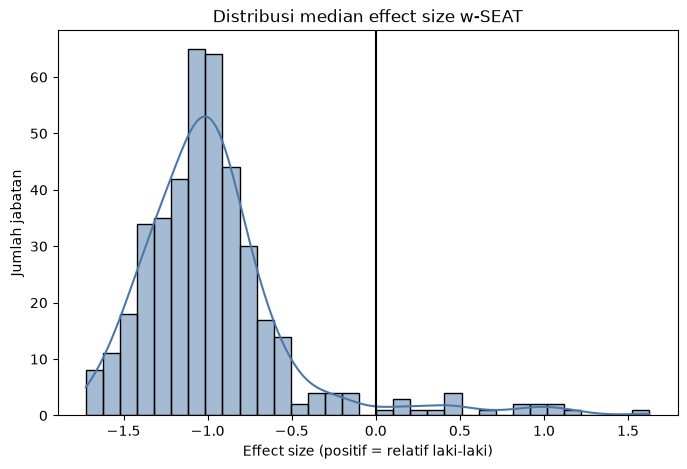

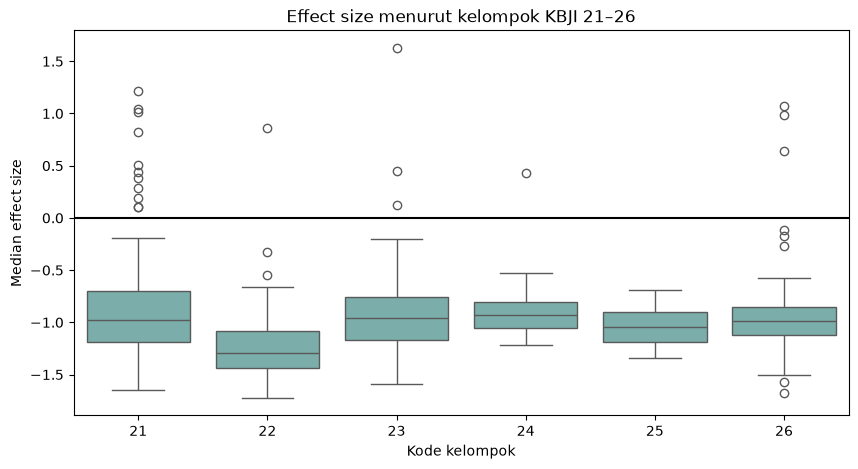

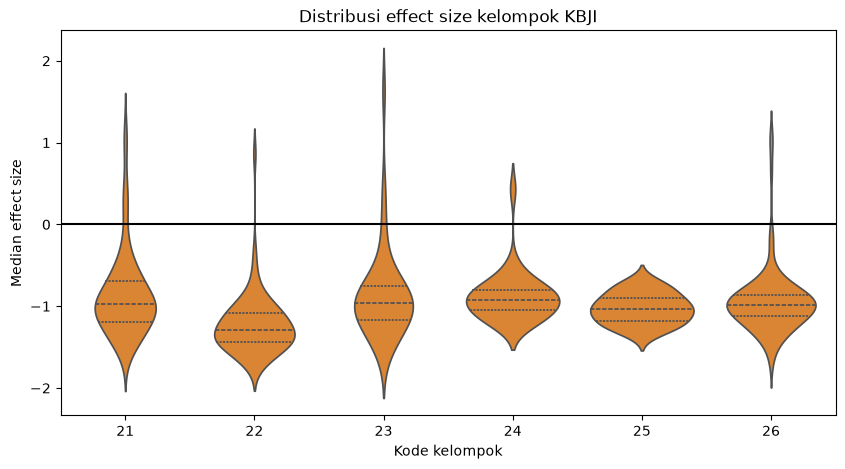

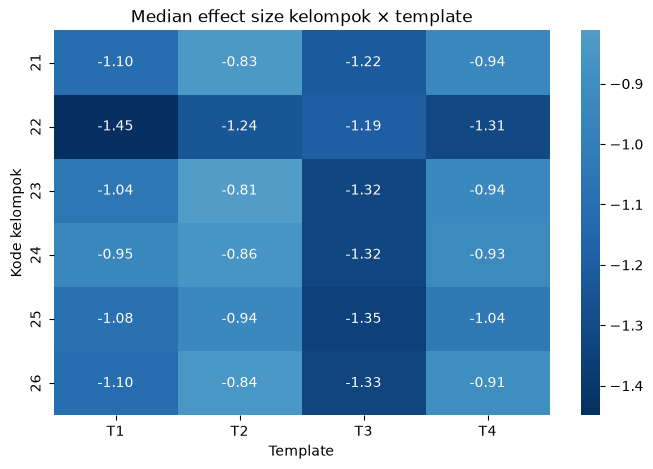

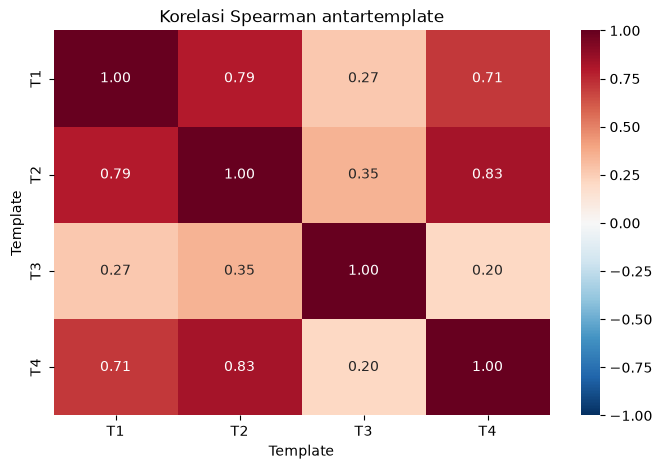

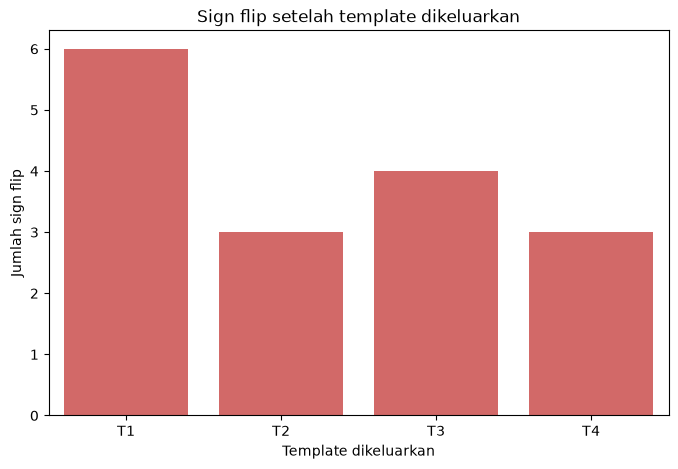

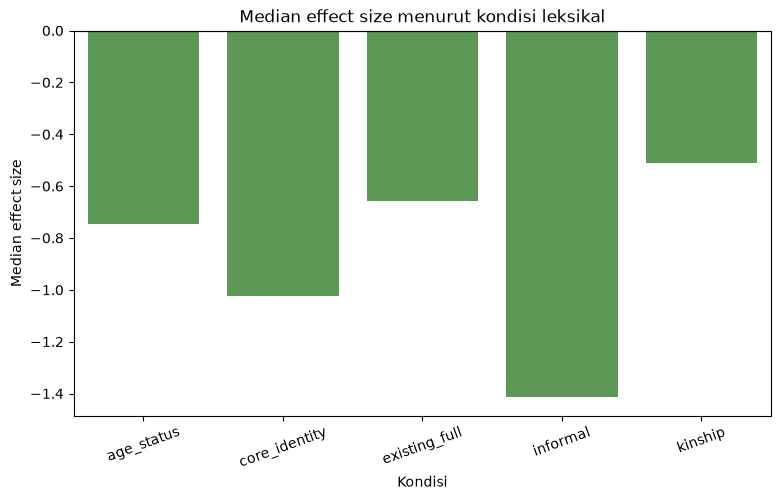

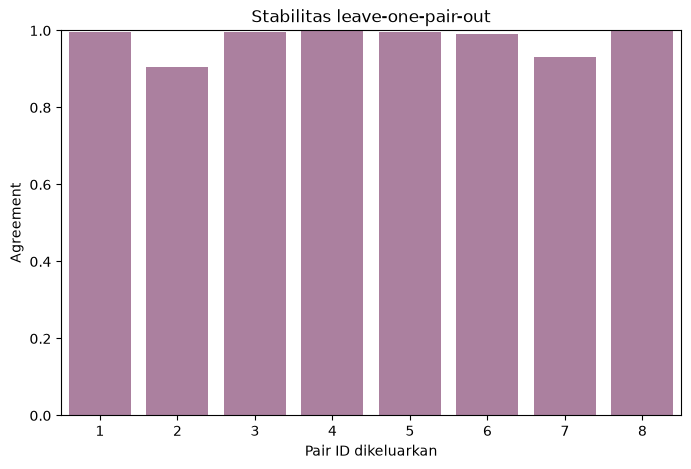

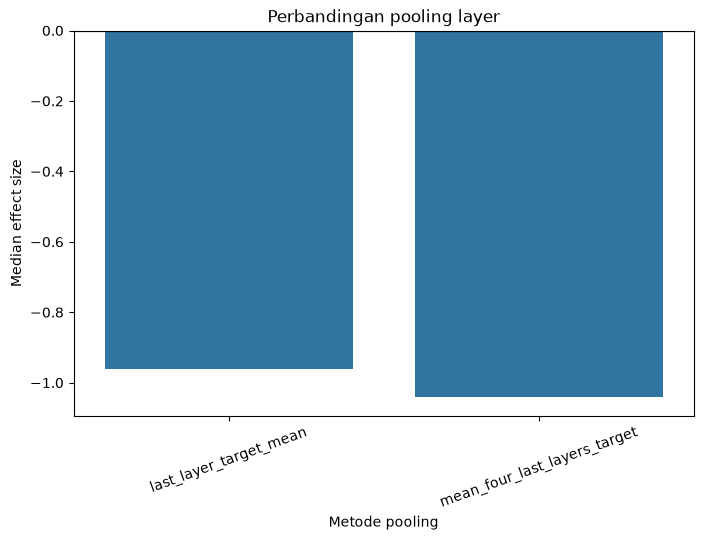

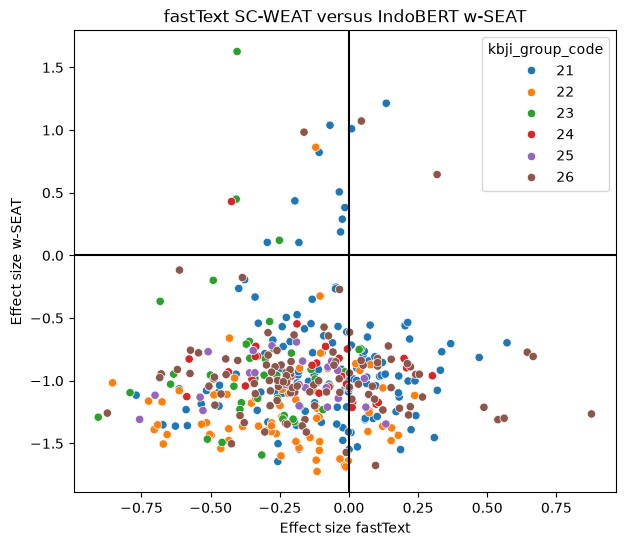

In [14]:
plt.figure(figsize=(8,5)); sns.histplot(occupation_summary["median_effect_size"],kde=True,color="#4C78A8"); plt.axvline(0,color="black"); plt.title("Distribusi median effect size w-SEAT"); plt.xlabel("Effect size (positif = relatif laki-laki)"); plt.ylabel("Jumlah jabatan"); plt.show()
plt.figure(figsize=(10,5)); sns.boxplot(data=occupation_summary,x="kbji_group_code",y="median_effect_size",color="#72B7B2"); plt.axhline(0,color="black"); plt.title("Effect size menurut kelompok KBJI 21–26"); plt.xlabel("Kode kelompok"); plt.ylabel("Median effect size"); plt.show()
plt.figure(figsize=(10,5)); sns.violinplot(data=occupation_summary,x="kbji_group_code",y="median_effect_size",inner="quartile",color="#F58518"); plt.axhline(0,color="black"); plt.title("Distribusi effect size kelompok KBJI"); plt.xlabel("Kode kelompok"); plt.ylabel("Median effect size"); plt.show()
hg=main_scores.groupby(["kbji_group_code","template_id"])["effect_size"].median().unstack(); plt.figure(figsize=(8,5)); sns.heatmap(hg,center=0,cmap="RdBu_r",annot=True,fmt=".2f"); plt.title("Median effect size kelompok × template"); plt.xlabel("Template"); plt.ylabel("Kode kelompok"); plt.show()
plt.figure(figsize=(8,5)); sns.heatmap(pm.corr(method="spearman"),vmin=-1,vmax=1,center=0,cmap="RdBu_r",annot=True,fmt=".2f"); plt.title("Korelasi Spearman antartemplate"); plt.xlabel("Template"); plt.ylabel("Template"); plt.show()
plt.figure(figsize=(8,5)); sns.barplot(data=leave_one_template_out,x="omitted_template",y="sign_flip_count",color="#E45756"); plt.title("Sign flip setelah template dikeluarkan"); plt.xlabel("Template dikeluarkan"); plt.ylabel("Jumlah sign flip"); plt.show()
plt.figure(figsize=(9,5)); sns.barplot(data=lexical_condition_comparison.groupby("lexical_condition")["median_effect_size"].median().reset_index(),x="lexical_condition",y="median_effect_size",color="#54A24B"); plt.axhline(0,color="black"); plt.title("Median effect size menurut kondisi leksikal"); plt.xlabel("Kondisi"); plt.ylabel("Median effect size"); plt.xticks(rotation=20); plt.show()
plt.figure(figsize=(8,5)); sns.barplot(data=leave_one_pair_out.groupby("omitted_pair_id")["sign_agreement_with_full"].mean().reset_index(),x="omitted_pair_id",y="sign_agreement_with_full",color="#B279A2"); plt.ylim(0,1); plt.title("Stabilitas leave-one-pair-out"); plt.xlabel("Pair ID dikeluarkan"); plt.ylabel("Agreement"); plt.show()
plt.figure(figsize=(8,5)); sns.barplot(data=pooling_comparison,x="embedding_method",y="median_effect_size",errorbar=None); plt.axhline(0,color="black"); plt.title("Perbandingan pooling layer"); plt.xlabel("Metode pooling"); plt.ylabel("Median effect size"); plt.xticks(rotation=20); plt.show()
if len(fasttext_comparison):
    plt.figure(figsize=(7,6)); sns.scatterplot(data=fasttext_comparison,x="fasttext_scweat_effect_size",y="wseat_median_effect_size",hue="kbji_group_code"); plt.axhline(0,color="black"); plt.axvline(0,color="black"); plt.title("fastText SC-WEAT versus IndoBERT w-SEAT"); plt.xlabel("Effect size fastText"); plt.ylabel("Effect size w-SEAT"); plt.show()


Grafik merangkum pola asosiasi model dan sensitivitas prosedur. Jabatan ekstrem tidak boleh disebut paling bias tanpa melihat agreement, CI, template, pooling, dan batas intrinsic/downstream.


## Menyimpan output dan interpretasi faktual

Semua tabel disimpan di outputs/tables dengan prefix test2_v5. Ringkasan angka dibuat setelah perhitungan aktual.


In [15]:
outputs={"test2_v5_contextual_embedding_audit.csv":contextual_embedding_audit,"test2_v5_wseat_scores_long.csv":wseat_scores_long,"test2_v5_occupation_summary.csv":occupation_summary,"test2_v5_group_summary.csv":group_summary,"test2_v5_template_stability.csv":template_stability,"test2_v5_leave_one_template_out.csv":leave_one_template_out,"test2_v5_leave_one_pair_out.csv":leave_one_pair_out,"test2_v5_lexical_condition_comparison.csv":lexical_condition_comparison,"test2_v5_pooling_comparison.csv":pooling_comparison,"test2_v5_fasttext_comparison.csv":fasttext_comparison,"test2_v5_statistical_tests.csv":statistical_tests,"test2_v5_posthoc_dunn.csv":posthoc_dunn}
for name,frame in outputs.items(): frame.to_csv(TABLE_DIR/name,index=False,encoding="utf-8-sig")
positive=int((occupation_summary["median_effect_size"]>0).sum()); negative=int((occupation_summary["median_effect_size"]<0).sum())
display(pd.DataFrame([{"question":"distribusi","answer":f"{positive} positif dan {negative} negatif pada core/last layer."},{"question":"kelompok","answer":f"Median kelompok berada pada {group_summary['median_effect_size'].min():.4f} sampai {group_summary['median_effect_size'].max():.4f}."},{"question":"template","answer":f"LOO Spearman {leave_one_template_out['spearman'].min():.4f} sampai {leave_one_template_out['spearman'].max():.4f}."},{"question":"pooling","answer":f"Agreement pooling {pooling_summary.loc[pooling_summary['metric'].eq('sign agreement'),'value'].iloc[0]:.4f}."},{"question":"baseline","answer":f"{len(fasttext_comparison)} jabatan matched dengan fastText."},{"question":"batas","answer":"Hasil tidak membuktikan diskriminasi, perilaku manusia, atau profesi diperuntukkan bagi gender tertentu."}]))


,question,answer
0,distribusi,19 positif dan 396 negatif pada core/last layer.
1,kelompok,Median kelompok berada pada -1.2933 sampai -0....
2,template,LOO Spearman 0.9493 sampai 0.9573.
3,pooling,Agreement pooling 0.9831.
4,baseline,401 jabatan matched dengan fastText.
5,batas,"Hasil tidak membuktikan diskriminasi, perilaku..."


## Quality control final dan metadata

QC mencakup model, data/kelompok, alignment, finite score, jumlah observasi, template, permutation resolution, duplikasi, dan output. Metadata menyimpan revision, library, seed, kondisi, pooling, bootstrap, dan durasi.


In [16]:
quality_rows=[{"check":"model sesuai","status":MODEL_NAME=="indobenchmark/indobert-base-p1","observed":MODEL_NAME},{"check":"415 jabatan dan enam kelompok","status":len(occupation_summary)==415 and set(occupation_summary["kbji_group_code"])==allowed_groups,"observed":[len(occupation_summary),sorted(occupation_summary["kbji_group_code"].unique())]},{"check":"alignment matched","status":contextual_embedding_audit["alignment_status"].eq("matched").all(),"observed":contextual_embedding_audit["alignment_status"].value_counts().to_dict()},{"check":"score finite","status":bool(np.isfinite(wseat_scores_long[["association_score","effect_size","permutation_p","fdr_p"]].to_numpy()).all()),"observed":int(wseat_scores_long.isna().sum().sum())},{"check":"jumlah observasi sesuai","status":len(wseat_scores_long)==len(df_analysis)*len(template_catalog)*len(embedding_methods)*len(condition_pairs),"observed":len(wseat_scores_long)},{"check":"template lengkap","status":bool((main_scores.groupby("occupation_code").size()==len(template_catalog)).all()),"observed":main_scores.groupby("occupation_code").size().value_counts().to_dict()},{"check":"partition tercatat","status":wseat_scores_long["exact_partition_count"].notna().all(),"observed":sorted(wseat_scores_long["exact_partition_count"].unique().tolist())},{"check":"tidak ada duplikat","status":not wseat_scores_long.duplicated(["occupation_code","template_id","lexical_condition","embedding_method"]).any(),"observed":int(wseat_scores_long.duplicated(["occupation_code","template_id","lexical_condition","embedding_method"]).sum())}]
quality_control=pd.DataFrame(quality_rows); quality_control.to_csv(TABLE_DIR/"test2_v5_quality_control.csv",index=False,encoding="utf-8-sig"); display(quality_control)
metadata={"version":"test2_v5","notebook":"test2_v5_indobert_wseat_pipeline.ipynb","model_name":MODEL_NAME,"model_revision":MODEL_REVISION,"tokenizer":tokenizer.__class__.__name__,"python_version":platform.python_version(),"pytorch_version":torch.__version__,"transformers_version":transformers.__version__,"device":str(device),"random_seed":RANDOM_SEED,"n_data_total":len(df),"n_analysis":len(df_analysis),"kbji_groups":sorted(allowed_groups),"templates":template_catalog["template_id"].tolist(),"embedding_methods":embedding_methods,"lexical_conditions":list(condition_pairs),"main_embedding_method":"last_layer_target_mean","aggregation":"median across templates","bootstrap_repetitions":BOOTSTRAP_REPETITIONS,"fasttext_matched_occupations":len(fasttext_comparison),"time_start":TIME_START_ISO,"time_end":time.strftime("%Y-%m-%dT%H:%M:%S%z"),"duration_seconds":time.time()-TIME_START,"quality_control_passed":bool(quality_control["status"].all())}
(TABLE_DIR/"test2_v5_run_metadata.json").write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding="utf-8"); assert quality_control["status"].all(); print("QC test2_v5 lulus; durasi detik:",round(metadata["duration_seconds"],2))


,check,status,observed
0,model sesuai,True,indobenchmark/indobert-base-p1
1,415 jabatan dan enam kelompok,True,"[415, [21, 22, 23, 24, 25, 26]]"
2,alignment matched,True,{'matched': 3448}
3,score finite,True,0
4,jumlah observasi sesuai,True,16600
5,template lengkap,True,{4: 415}
6,partition tercatat,True,"[2, 6, 20, 12870]"
7,tidak ada duplikat,True,0


QC test2_v5 lulus; durasi detik: 69.78


## Referensi metodologis

Caliskan et al. (2017), May et al. (2019), Steinhauer (2010), Antoniak dan Mimno (2021), Husse dan Spitz (2022), Steinborn et al. (2022), dan Wilie et al. (2020). Model: indobenchmark/indobert-base-p1 dari Hugging Face Hub.
